# 04 — Identifiability of r (and the η–r degeneracy)

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

The model has three unknowns: the noise $\eta$, the interaction radius $r$ and the speed $v_0$.

**What the earlier steps found:**
- **[notebook 01](01_observables.ipynb)** looked at each summary statistic separately. In the φ-type summaries
  (polarization, velocity correlations), raising $\eta$ by 10% and raising $r$ by 10% have *opposite and
  nearly equal* effects. That is the signature of a **degeneracy**: data explained by $(\eta, r)$ can be
  explained almost as well by $(\eta', r')$ further along a line.
- **[notebook 03](03_point_fit.ipynb)** fitted all three parameters at once with the 7-summary vector and found the
  truth within ~1.5%. But the likelihood was much wider in $r$ than in $\eta$ and $v_0$.

**The question here:** *how well* is $r$ determined by one observed run, *which summaries* provide that
information, and does the η–r degeneracy from notebook 01 survive when all summaries are used together?

**The same design and data as notebook 03:** N = 40 particles, box L = 10 (ρ = 0.4), true θ* = (η, r, v₀) = (2, 1, 0.03).
Positions are observed every k = 10 steps, and one run is 501 frames after a 5000-step burn-in.

**The protocol was written down before running**, including the summary subsets and the
thresholds. The subsets were fixed *before* seeing which one gives the nicest ridge.

**Roadmap:**

| § | question | tool |
|---|---|---|
| 1 | Is r identified? (Q1) | Fisher information → standard errors |
| 2 | Which summaries carry r? Where is the degeneracy? (Q2) | the same, for subsets of summaries, plus a picture |
| 3 | Can the local (quadratic) picture be trusted? (Q3) | profile likelihood of r |
| 4 | Which box size identifies r best? (Q4) | Fisher at three densities |
| 5 | What does the degeneracy look like? | two flocks along the ridge, side by side |
| 6 | What this taught us | |

## Definitions — the tools, with intuition first

### The idea in one paragraph

Fitting θ means looking for the θ whose simulated summaries look like the observed ones. A parameter is
well identified if changing it a little moves the summaries **a lot compared with their run-to-run noise**.
The Fisher information makes this precise for all parameters and all summaries at once, *including the
fact that summaries are correlated with each other*. Two summaries that always fluctuate together count
as one piece of evidence, not two. A **standard error** then says how precisely one run pins each
parameter down, and a **correlation** between two parameters says whether their errors trade off, i.e.
whether there is a ridge.

### The ingredients (`flockladder.sensitivity`, `flockladder.fisher`)

We simulate $B = 200$ independent runs at θ*. Each gives a vector of summaries $\mathbf s_b \in \mathbb R^d$
(the time averages defined in the [notebook 01 notebook](01_observables.ipynb) §3).

**1. How the summaries respond to each parameter.** For each parameter $q \in \{\eta, r, v_0\}$, rerun
every replica with $\theta_q$ multiplied by $e^{\pm 0.1}$ (±10%), using the *same random numbers*, and take
the difference:

$$\mathbf D_{b,q} = \frac{\mathbf s_b^{+q} - \mathbf s_b^{-q}}{0.2} \approx \frac{\partial \mathbf s}{\partial \log\theta_q},
\qquad J = \frac1B\sum_b \mathbf D_b \quad (d \times 3)$$

Column $q$ of $J$ is the change in every summary per unit change of $\log\theta_q$. Working in logs means
"per relative change", so the three parameters are comparable despite their very different sizes.

**2. How noisy and how correlated the summaries are.** $\Sigma = \widehat{\mathrm{Cov}}(\mathbf s_b)$ is the
$d\times d$ covariance across runs.

**3. The Fisher information of one run:**

$$I = J^\top \Sigma^{-1} J \qquad (3\times 3)$$

Read it as the "signal / noise" of the summaries about θ. $\Sigma^{-1}$ first whitens the summaries, turning
correlated noisy summaries into independent unit-noise combinations. Then $J$ measures how far each
parameter moves those combinations. This is the expected curvature of the Gaussian synthetic likelihood
of notebook 03 (from its mean term).

**4. From information to uncertainty.** The inverse $I^{-1}$ is the (approximate) covariance of the
estimate of $\log\theta$ from one run:

$$\mathrm{se}(\log\theta_q) = \sqrt{(I^{-1})_{qq}}, \qquad
\mathrm{corr}(\log\theta_p, \log\theta_q) = \frac{(I^{-1})_{pq}}{\mathrm{se}_p\,\mathrm{se}_q}$$

- $\mathrm{se}(\log r) = 0.05$ means r is known to about ±5% (1 se), or ±10% at 95%.
- A correlation near **±1** means the data constrain only a *combination* of the two parameters: that is a
  ridge (degeneracy). Near 0 means they are determined independently.
- **Positive** correlation here means "larger η together with larger r" fits about as well. More noise
  is compensated by a longer alignment range.

**5. How uncertain are these numbers themselves?** They come from 200 simulated runs, so we bootstrap:
resample the 200 replicas with replacement (keeping each replica's $\mathbf s_b$ and $\mathbf D_b$ together),
recompute everything, and repeat 1000 times. The 2.5–97.5% range is reported as a 95% interval.

### Pre-registered criteria
- **Q1:** r is identified at 10% if $\mathrm{se}(\log r) < 0.05$.
- **Q2:** a summary set is *degenerate* in η–r if $|\mathrm{corr}(\log\eta, \log r)| > 0.9$.
- **Q3:** the profile likelihood agrees with the quadratic (Fisher) prediction within a factor 2 (defined in §3).

### Summary sets compared
- **Fit set (7):** speed, cos_turn, corr_0_1, corr_1_2, phi, n_clusters, nn_dist. This is the set used for fitting in notebook 03.
- **All 10:** the fit set plus corr_2_4, largest_cluster, chi (everything `flockladder.observables` computes).
- **φ-type (4):** phi, chi, corr_1_2, corr_2_4. These are the classic "how aligned is the flock"
  observables of the Vicsek literature, which is where notebook 01 saw the η–r trade-off.
- **Leave-one-out:** the fit set with one summary removed at a time (explained in §2).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from flockladder.animate import animate, show
from flockladder.fisher import bootstrap, fisher, local_info, summarize
from flockladder.results import load, unpack_fits, unpack_sensitivity
from flockladder.synlik import SUMMARIES, TRUTH, params, shrunk_cov, summary_matrix
from flockladder.vicsek import box_for_density, simulate

# The 200-replica runs behind the Fisher information (21 runs per density) and the profile fits are loaded from
# results/; scripts/a4_identifiability.py regenerates them with exactly the calls shown in the comments.
A = load("a4_identifiability")
RUN = dict(k=10, n_frames=501, burn_in=5000, n_replicas=200, seed=0)
# sensitivity(VicsekParams(eta=2.0, r=1.0, v0=0.03, n=40, L=box_for_density(40, rho)), **RUN) for each density:
sens = {rho: unpack_sensitivity(f"rho{rho}", A) for rho in (0.4, 1.0, 4.0)}
S7 = list(SUMMARIES)
ALL10 = S7 + ["corr_2_4", "largest_cluster", "chi"]
PHI_TYPE = ["phi", "chi", "corr_1_2", "corr_2_4"]


def analyse(rho, names, boot=True):
    li = local_info(sens[rho], names)
    out = summarize(fisher(li["V"], li["D"]))
    if boot:
        b = bootstrap(li["V"], li["D"])
        out["se_ci"] = np.percentile(b["se"], [2.5, 97.5], axis=0)
        out["corr_ci"] = np.percentile(b["corr"][:, 0, 1], [2.5, 97.5])
    return out

## 1. Q1 — is r identified?

Fisher analysis of the fit set at the design point (ρ = 0.4). The cell prints the standard error of each
log-parameter with its bootstrap interval, and the correlations between the parameters' errors.

In [2]:
a = analyse(0.4, S7)
for q, name in enumerate(("η", "r", "v₀")):
    lo, hi = a["se_ci"][:, q]
    print(f"se(log {name}) = {a['se'][q]:.4f}   (bootstrap 95%: {lo:.4f}–{hi:.4f})")
print(
    f"corr(log η, log r) = {a['corr'][0, 1]:+.2f}  (95%: {a['corr_ci'][0]:+.2f} to {a['corr_ci'][1]:+.2f})"
)
print(
    f"corr(log η, log v₀) = {a['corr'][0, 2]:+.2f},  corr(log r, log v₀) = {a['corr'][1, 2]:+.2f}"
)
print(
    f"\nQ1: se(log r) = {a['se'][1]:.3f} {'<' if a['se'][1] < 0.05 else '≥'} 0.05  ->  r {'IS' if a['se'][1] < 0.05 else 'is NOT'} identified at 10%"
)

se(log η) = 0.0164   (bootstrap 95%: 0.0148–0.0177)
se(log r) = 0.0231   (bootstrap 95%: 0.0202–0.0253)
se(log v₀) = 0.0055   (bootstrap 95%: 0.0050–0.0060)
corr(log η, log r) = +0.76  (95%: +0.70 to +0.81)
corr(log η, log v₀) = +0.99,  corr(log r, log v₀) = +0.74

Q1: se(log r) = 0.023 < 0.05  ->  r IS identified at 10%


**How to read this.**
- **se(log r) = 0.023:** one run determines r to about ±2.3% (1 se), or ±4.6% at 95%. That is well under the
  pre-registered 0.05, so **r is identified**. The bootstrap interval (0.020–0.025) shows the number is not a
  fluke of the 200 simulated runs.
- **For comparison:** η is known to ±1.6% and v₀ to ±0.55%. r is the least precise parameter, as the wide
  valley in notebook 03 suggested.
- **corr(log η, log r) = +0.76:** the errors in η and r are positively tied. An estimate with η a bit too
  high tends to have r a bit too high as well. This is a *tilt*, not a ridge (a ridge would be > 0.9).
- **corr(log η, log v₀) = +0.99:** this is nearly a ridge, yet both parameters are individually precise. The
  data pin one *combination* of η and v₀ extremely well (the apparent `speed`: more noise makes the net
  displacement shorter, so a larger v₀ compensates) and the other combination less well. That thin,
  curved valley is what made notebook 03's optimiser stall.

## 2. Q2 — which summaries carry r, and where is the degeneracy?

### The leave-one-out idea

To find out what each summary contributes, **remove it and see what gets worse**. For each summary in the
fit set, we redo the Fisher analysis with the other six only:

- If se(log r) **increases** a lot when a summary is removed, that summary was carrying information about r
  that the others do not have.
- If se(log r) barely changes, the summary was **redundant**: what it says about r is already said by the others.
  With summaries this correlated, that is common.
- If corr(log η, log r) **jumps towards 1** when a summary is removed, that summary was what **broke the
  η–r ridge**. Without it, the remaining summaries can only see the combination of η and r.

The table also shows the three reference sets: the fit set itself (the baseline to compare every row with),
all 10 summaries, and the φ-type set. The last column is the bootstrap 95% interval for the correlation. A
row is flagged `degenerate` when |corr| > 0.9.

In [3]:
rows = [("fit set (7)", S7), ("all 10", ALL10), ("φ-type", PHI_TYPE)]
rows += [(f"fit set − {s}", [x for x in S7 if x != s]) for s in S7]
print(f"{'set':26s} {'se η':>7s} {'se r':>7s} {'se v₀':>7s} {'corr(η,r)':>10s}  95% CI corr")
for name, names in rows:
    o = analyse(0.4, names)
    flag = "  <- degenerate" if abs(o["corr"][0, 1]) > 0.9 else ""
    print(
        f"{name:26s} {o['se'][0]:7.4f} {o['se'][1]:7.4f} {o['se'][2]:7.4f} {o['corr'][0, 1]:+10.2f}"
        f"  [{o['corr_ci'][0]:+.2f}, {o['corr_ci'][1]:+.2f}]{flag}"
    )

set                           se η    se r   se v₀  corr(η,r)  95% CI corr


fit set (7)                 0.0164  0.0231  0.0055      +0.76  [+0.70, +0.81]


all 10                      0.0149  0.0178  0.0050      +0.74  [+0.67, +0.80]
φ-type                      0.1777  0.1279  2.0094      +0.97  [+0.78, +1.00]  <- degenerate


fit set − speed             0.0271  0.0231  0.4106      +0.47  [+0.14, +0.72]
fit set − cos_turn          0.0322  0.0408  0.0115      +0.93  [+0.90, +0.95]  <- degenerate


fit set − corr_0_1          0.0166  0.0312  0.0056      +0.66  [+0.58, +0.72]
fit set − corr_1_2          0.0198  0.0252  0.0067      +0.80  [+0.74, +0.85]


fit set − phi               0.0166  0.0238  0.0056      +0.76  [+0.70, +0.81]
fit set − n_clusters        0.0184  0.0277  0.0061      +0.81  [+0.76, +0.86]


fit set − nn_dist           0.0165  0.0250  0.0056      +0.64  [+0.56, +0.71]


**How to read the table.** Compare each row with the first row (fit set: se r = 0.0231, corr = +0.76).

- **φ-type set: corr = +0.97 → degenerate.** With only the "how aligned" observables, the errors in η and r are
  almost perfectly tied: these summaries cannot separate *more noise* from *shorter alignment range*.
  Individually both se's are large (0.18 and 0.13, i.e. ±18% and ±13%) and v₀ is not determined at all
  (se 2.0: these summaries do not respond to v₀).
- **Removing `cos_turn` → corr = +0.93, degenerate again**, and se(log η) doubles (0.016 → 0.032). `cos_turn`
  (the mean cosine of the turning angle between frames) is the summary that breaks the ridge. It sees the
  per-step noise almost directly, however far alignment reaches.
- **Removing `corr_0_1` → se(log r) goes from 0.023 to 0.031**, the largest loss for r. The short-range velocity
  correlation (pairs closer than 1) is the main carrier of r: it measures how aligned *neighbours* are, which
  depends directly on who counts as a neighbour.
- **Removing `speed` → se(log v₀) goes from 0.0055 to 0.41**: v₀ is essentially determined by `speed` alone.
  (Its effect on r is nil, which is consistent with notebook 01.)
- **Removing `phi`** changes almost nothing: in the presence of the other summaries, φ is redundant.
- **Removing `n_clusters`, `corr_1_2` or `nn_dist`** worsens se(log r) a little (0.025–0.028). They add some
  geometric information about r.
- **Removing `corr_0_1` or `nn_dist` *lowers* corr(η, r)** (to 0.66 and 0.64), while making se(log r) worse.
  So these summaries sharpen r in a direction that is partly tied to η. More information and less correlation
  are not the same thing; what matters for the fit is the se.
- **All 10 summaries:** se(log r) improves to 0.018. The three extra summaries help a little.

### The picture: likelihood on the (η, r) plane, full set against φ-type set

This reuses the simulations of notebook 03 (stored in `results/`): an 11 × 11 grid in (η, r) at the
true v₀ = 0.03, with 40 runs per point. No new simulations are needed. The likelihood is recomputed with the
two summary sets.
- Each panel shows ℓ minus its own maximum, clipped at −60; yellow is best.
- The **white contour** marks ℓ = max − 3, a rough "plausible region".
- The red star is the truth θ*.

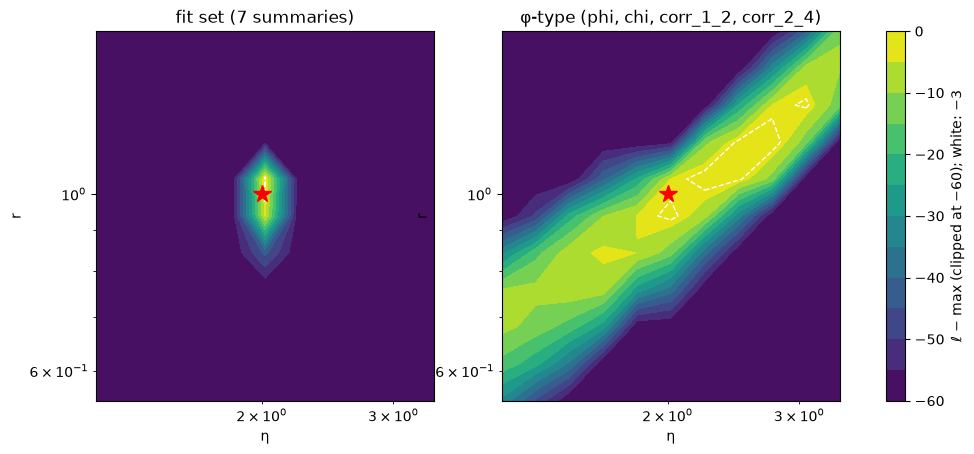

In [4]:
G_ETA = np.exp(np.linspace(np.log(1.2), np.log(3.4), 11))
G_R = np.exp(np.linspace(np.log(0.55), np.log(1.6), 11))

# The summaries (all 10) of the 40 runs at every grid point of notebook 03, and of the observed run:
GRID_S, NAMES10, OBS10 = A["grid_summaries"], list(A["grid_summary_names"]), A["obs_all10"]


def ell(i_r, i_eta, names):
    idx = [NAMES10.index(n) for n in names]
    S = GRID_S[i_r, i_eta][:, idx]
    x = OBS10[idx]
    C = shrunk_cov(S)[0]
    d = x - S.mean(0)
    return -0.5 * d @ np.linalg.solve(C, d) - 0.5 * np.linalg.slogdet(C)[1]


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, names) in zip(
    axes, (("fit set (7 summaries)", S7), ("φ-type (phi, chi, corr_1_2, corr_2_4)", PHI_TYPE))
):
    Z = np.array([[ell(i, j, names) for j in range(len(G_ETA))] for i in range(len(G_R))])
    Z = Z - Z.max()
    cs = ax.contourf(G_ETA, G_R, np.maximum(Z, -60), levels=np.linspace(-60, 0, 13), cmap="viridis")
    ax.contour(G_ETA, G_R, Z, levels=[-3], colors="w", linewidths=1)
    ax.plot(*TRUTH[:2], "r*", ms=13)
    ax.set(xscale="log", yscale="log", xlabel="η", ylabel="r", title=title)
fig.colorbar(cs, ax=axes, label="ℓ − max (clipped at −60); white: −3")

**How to read the picture.**
- **Left (fit set):** a compact peak centred on the truth. Narrow in η, a bit longer in r. This is the "tilt,
  not ridge" of §1.
- **Right (φ-type set):** a **long diagonal ridge** running from small (η, r) to large (η, r). Any point on it
  explains the alignment summaries about equally well. Worse, the maximum sits *off* the truth, around
  η ≈ 2.3–2.8 and r ≈ 1.1–1.3, displaced along the ridge. With only φ-type observables, a fit would
  confidently return the wrong (η, r) with no warning from the optimiser.

This two-panel figure is the central result of the series.

## 3. Q3 — can the local (quadratic) picture be trusted? The profile of r

The Fisher analysis is **local**: it treats the log-likelihood as a parabola around the truth, with
curvature $I$. That is exact for small changes and can be wrong for larger ones. To check it, we compute the
**profile likelihood** of r directly:

$$\ell_p(r) = \max_{\eta,\,v_0}\ \ell(\eta, r, v_0)$$

At each fixed r, the other two parameters are re-optimised, because they can partly compensate (the tilt of
§1). The drop $\ell_p(1) - \ell_p(r)$ then says how much worse the *best* explanation with that r is.

If the parabola is right, the drop should be

$$\ell_p(1) - \ell_p(r) \approx \frac{(\log r)^2}{2\,\mathrm{se}(\log r)^2}$$

For example, with se = 0.023, r = 1.1 should cost about 8.5 units and r = 1.25 about 47. The pre-registered
criterion is agreement within a factor 2.

**Settings:**
- r ∈ {0.8, 0.9, 1.0, 1.1, 1.25}.
- At each r, Nelder–Mead over (log η, log v₀), starting from notebook 03's best fit.
- Initial steps = 2 × the Fisher se; at most 60 evaluations.
- The notebook 03 objective: B = 40 runs, shrunk covariance, seed 0.

The five profiles run in parallel.

    r    η̂(r)    v̂₀(r)      ℓ_p    drop  Fisher  ratio  evals
 0.80   2.0040   0.03001    -5.51    37.7    46.6   0.81  60
 0.90   2.0158   0.03009    13.81    18.3    10.4   1.77  60
 1.00   2.0161   0.03007    32.15     0.0     0.0    nan  60
 1.10   2.0933   0.03035    21.00    11.1     8.5   1.31  60
 1.25   1.9897   0.02983   -69.60   101.7    46.6   2.18  60


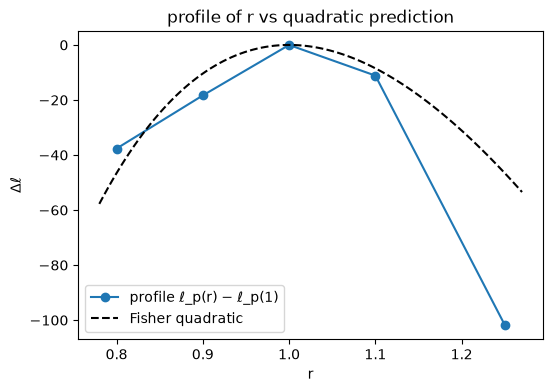

In [5]:
RS = [0.8, 0.9, 1.0, 1.1, 1.25]
prof = unpack_fits(
    "profile", A
)  # profile_many(observed(), RS, np.array([2.0035, 0.03001]), step=2 * a["se"][[0, 2]], workers=5)
lp = np.array([f.loglik for f in prof])
i0 = RS.index(1.0)
drop = lp[i0] - lp
pred = 0.5 * np.log(np.array(RS)) ** 2 / a["se"][1] ** 2
print(
    f"{'r':>5s} {'η̂(r)':>8s} {'v̂₀(r)':>9s} {'ℓ_p':>8s} {'drop':>7s} {'Fisher':>7s} {'ratio':>6s}  evals"
)
for r, f, dr, pr in zip(RS, prof, drop, pred):
    ratio = dr / pr if pr > 0 else np.nan
    print(
        f"{r:5.2f} {f.theta[0]:8.4f} {f.theta[2]:9.5f} {f.loglik:8.2f} {dr:7.1f} {pr:7.1f} {ratio:6.2f}  {f.nfev}"
    )

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(RS, -drop, "o-", label="profile ℓ_p(r) − ℓ_p(1)")
rr = np.linspace(0.78, 1.27, 100)
ax.plot(rr, -0.5 * np.log(rr) ** 2 / a["se"][1] ** 2, "k--", label="Fisher quadratic")
ax.set(xlabel="r", ylabel="Δℓ", title="profile of r vs quadratic prediction")
ax.legend();

**How to read this.**
- The **ratio** column is (measured drop) / (parabola prediction): 1 means perfect agreement. We get 0.8,
  1.8, 1.3 and 2.2. Three of four are within the factor 2; r = 1.25 is just outside.
- The profile is **asymmetric**: going to r = 1.25 costs 102 units, while r = 0.8 (the same distance in log r)
  costs 38. Increasing r is penalised more. A plausible reason is that the number of neighbours grows like
  r², so the summaries react faster to a larger radius than to a smaller one. A parabola cannot capture that.
- **Two caveats both push the ratios up:**
  - Every profile fit used all 60 evaluations, so the inner maximisation may not be complete, and the
    measured drops may be overestimated.
  - The profile uses the B = 40 likelihood, which notebook 03's follow-up showed is artificially sharper than the
    B = 200 estimate used for $I$.
- **Verdict:** the Fisher se gives the right *order of magnitude* (a few percent for r), quickly. A trustworthy
  interval is what [notebook 05](05_bootstrap.ipynb) sets out to add.

## 4. Q4 — which box size identifies r best?

A design question: if we could choose the arena size for the same 40 particles, which would identify r best?
We repeat the Fisher analysis of §1 (fit set, same θ*, same run length) for three boxes:
- ρ = 0.4 (L = 10, the design point);
- ρ = 1 (L = 6.3);
- ρ = 4 (L = 3.2, the dense box of notebook 00).

**Expectation going in:** notebook 00 and notebook 01 argued the dense box was "nearly fully connected and trivial", so it
should identify r worse.

In [6]:
print(
    f"{'ρ':>5s} {'L':>6s} {'se η':>7s} {'se r':>7s} {'se v₀':>7s} {'corr(η,r)':>10s}   se r 95% CI"
)
for rho in (0.4, 1.0, 4.0):
    o = analyse(rho, S7)
    print(
        f"{rho:5.1f} {box_for_density(40, rho):6.2f} {o['se'][0]:7.4f} {o['se'][1]:7.4f} {o['se'][2]:7.4f}"
        f" {o['corr'][0, 1]:+10.2f}   [{o['se_ci'][0, 1]:.4f}, {o['se_ci'][1, 1]:.4f}]"
    )
print(
    "\nsummaries constant across replicas carry no information and are dropped by flockladder.fisher.fisher:"
)
print(
    "  sd of n_clusters across replicas:",
    {rho: round(float(sens[rho]["n_clusters"]["value"].std()), 4) for rho in sens},
)

    ρ      L    se η    se r   se v₀  corr(η,r)   se r 95% CI


  0.4  10.00  0.0164  0.0231  0.0055      +0.76   [0.0202, 0.0253]


  1.0   6.32  0.0154  0.0241  0.0050      +0.78   [0.0216, 0.0263]


  4.0   3.16  0.0070  0.0154  0.0022      +0.75   [0.0133, 0.0168]

summaries constant across replicas carry no information and are dropped by flockladder.fisher.fisher:
  sd of n_clusters across replicas: {0.4: 0.677, 1.0: 0.1713, 4.0: 0.0003}


**How to read this — a result against our expectation.**
- The **dense box identifies r best**: se(log r) = 0.015 against 0.023–0.024 for the sparser boxes. It also
  identifies η and v₀ about 2× better.
- **Why.** In the dense box every run is almost identical: the flock is one ordered cluster with tiny
  fluctuations (notebook 01 found run-to-run sds several times smaller, e.g. 0.011 vs 0.038 for time-averaged φ). Small noise means that even small responses to r are
  detectable. The dense box has *fewer kinds* of information (the geometry is dead: `n_clusters` is exactly 1
  in every run, so it carries nothing and is dropped), but each remaining summary is far more *precise*.
- The sparse and intermediate boxes are about equal.
- **Why we keep ρ = 0.4 anyway.** It resembles what tracking experiments with groups that
  split and merge look like, and it exercises the geometric summaries. This is now a documented trade-off, not a
  claim that sparse is more informative.

## 5. Seeing the ridge: two flocks along the φ-type weak direction

The goal is to *see* the degeneracy.
- Among all directions in the (log η, log r) plane (v₀ fixed), find the one along which the **φ-type
  summaries change least**. That is the eigenvector $\mathbf v$ of the smallest eigenvalue $\lambda_{\min}$
  of the φ-type Fisher information restricted to (η, r).
- Place two parameter sets symmetrically at $\pm t\,\mathbf v$ from the truth, with t chosen so that r
  differs by ±15%.

**How different are they?** We measure the separation in **whitened units**:

$$\Delta = \sqrt{\mathbf d^\top \Sigma^{-1} \mathbf d}$$

Here $\mathbf d$ is the difference of their mean summaries and Σ the run-to-run covariance. Δ counts how
many run-to-run standard deviations apart the two sets are, taking correlations into account. Δ ≈ 1 means
a single run cannot tell them apart; Δ ≫ 1 means one run easily can. The Fisher prediction is
$\Delta \approx 2t\sqrt{\lambda_{\min}}$.

We compute Δ for three sets of summaries: two φ-type ones in the fit set (phi, corr_1_2), cos_turn alone,
and the whole fit set. The video shows both flocks, same seed, coloured by cluster size.

weakest φ-type direction in (log η, log r): [0.871 0.49 ];  eigenvalues [  53.3 2763. ];  se along it = 0.137
θ = [1.56 0.87 0.03]:  phi=0.551  corr_1_2=0.710  cos_turn=0.831  speed=0.027  nn_dist=0.469
θ = [2.564 1.15  0.03 ]:  phi=0.442  corr_1_2=0.616  cos_turn=0.587  speed=0.022  nn_dist=0.612

whitened separation Δ: φ-type subset in the fit set (phi, corr_1_2) = 3.1,  cos_turn alone = 16.4,  fit set (7) = 194.9
Fisher prediction for the φ-type set: Δ ≈ 4.2


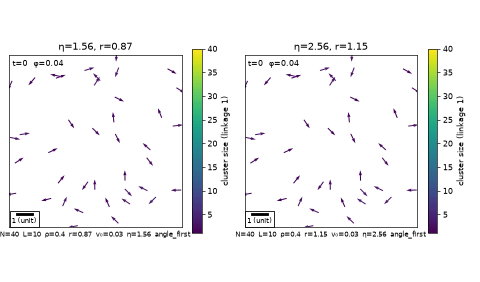

In [7]:
li = local_info(sens[0.4], PHI_TYPE)
I2 = fisher(li["V"], li["D"])[:2, :2]
w, U = np.linalg.eigh(I2)
v = U[:, 0] * np.sign(U[1, 0])  # weakest direction, pointing to larger r
t = np.log(1.15) / v[1]
pair = [TRUTH * np.exp(np.r_[-t * v, 0]), TRUTH * np.exp(np.r_[t * v, 0])]
print(
    f"weakest φ-type direction in (log η, log r): {v.round(3)};  eigenvalues {w.round(1)};"
    f"  se along it = {1 / np.sqrt(w[0]):.3f}"
)
M = [summary_matrix(th, 40, 0) for th in pair]
V200 = {n: sens[0.4][n]["value"] for n in SUMMARIES}


def whitened(names):
    idx = [SUMMARIES.index(n) for n in names]
    d = M[1][:, idx].mean(0) - M[0][:, idx].mean(0)
    C = np.atleast_2d(np.cov(np.stack([V200[n] for n in names], -1), rowvar=False))
    return float(np.sqrt(d @ np.linalg.solve(C, d)))


for th, Mi in zip(pair, M):
    print(
        f"θ = {th.round(3)}:  "
        + "  ".join(
            f"{n}={Mi[:, SUMMARIES.index(n)].mean():.3f}"
            for n in ("phi", "corr_1_2", "cos_turn", "speed", "nn_dist")
        )
    )
print(
    f"\nwhitened separation Δ: φ-type subset in the fit set (phi, corr_1_2) = {whitened(['phi', 'corr_1_2']):.1f},"
    f"  cos_turn alone = {whitened(['cos_turn']):.1f},  fit set (7) = {whitened(list(SUMMARIES)):.1f}"
)
print(f"Fisher prediction for the φ-type set: Δ ≈ {2 * t * np.sqrt(w[0]):.1f}")
trs = [simulate(params(th), 1500, seed=7, record_every=3) for th in pair]
gif = animate(
    trs,
    "phi_ridge_pair",
    color="cluster",
    gif=Path("../figures/phi_ridge_pair.gif"),
    stride=3,
    fps=15,
    dpi=60,
    titles=[f"η={pair[0][0]:.2f}, r={pair[0][1]:.2f}", f"η={pair[1][0]:.2f}, r={pair[1][1]:.2f}"],
)
show(gif)

**How to read this.**
- **The two parameter sets are far apart:** η = 1.56 vs 2.56 (a factor 1.6) and r = 0.87 vs 1.15.
- **Yet in (phi, corr_1_2) they are only Δ ≈ 3 run-sds apart.** Compare the Fisher prediction of 4.2 for the
  full φ-type set. A single run could barely distinguish them from alignment observables alone, and with
  some tracking noise it could not.
- **In `cos_turn` alone they are 16 sds apart**, and in the full fit set about 195. The turning angle
  immediately gives away which flock is noisier.
- **About the video:** the two flocks look clearly different to the eye. The left one (less noise, shorter
  radius) forms a large aligned group; the right one (more noise, longer radius) stays scattered in small
  groups. Even the time-averaged φ differs (0.55 vs 0.44). Yet because φ, chi and the correlations fluctuate
  *together* from run to run, their joint difference is only ~3 run-sds. The degeneracy is not "identical
  movies". It is "*hard to tell apart with the summaries you chose to measure*", which is why that choice
  matters and was fixed in advance.
- **Scale bar:** the bar in each panel has length 1, the unit of length (the true r* = 1). The panel's own r
  is in the parameter line underneath. That is exactly why the choice of summaries matters, and why it was fixed in advance.

## 6. What this taught us

**Q1 — r is identified from one run:** se(log r) = 0.023 (bootstrap 95%: 0.020–0.025), well under the 0.05
threshold. So a single run of N = 40 over 5000 steps pins r to about ±5% (2 se). η gets ±3%, v₀ ±1%.
*If the only question is "is r identifiable at this design?", stop here.*

**Q2 — the η–r degeneracy is real, but only for φ-type summaries.**
- **φ-type set (phi, chi, corr_1_2, corr_2_4):** corr(log η, log r) = +0.97, so it is **degenerate**
  by the pre-registered criterion. The (η, r) map in §2 is a long diagonal ridge: more noise is offset by
  a larger interaction radius. Its maximum lies *off* θ*, displaced along the ridge.
- **With the fit set:** corr = +0.76, a moderate tilt rather than a ridge. The peak is compact and centred
  on θ*.
- **`cos_turn` is what breaks the ridge.** Leaving it out brings the correlation back to 0.93 (degenerate)
  and nearly doubles se(log r). Turning angles see the per-step noise almost directly, independently of
  how far the alignment reaches.
- **Where r comes from:** `corr_0_1` (se(log r) 0.023 → 0.031 without it), then `n_clusters`, `corr_1_2`
  and `nn_dist`. With all 10 summaries se(log r) = 0.018: the extra summaries (corr_2_4,
  largest_cluster, chi) add a little.
- **The same Fisher analysis quantifies notebook 03's valley:** corr(log η, log v₀) = +0.99. The two parameters
  are individually precise, but their combination along constant `speed` is nearly free. That is the
  thin curved valley that stalled Nelder–Mead.

**Seeing it (§5):** a pair 30% apart in r along the φ-type weak direction is only ~3 run-sd apart in
(phi, corr_1_2). It is 16 sd apart in cos_turn alone, and ~195 sd apart in the 7-summary vector.

**Q3 — the quadratic picture holds to about a factor 2, not better.**
- Profile drop / Fisher prediction = 0.8, 1.8, 1.3 and 2.2 at r = 0.8, 0.9, 1.1 and 1.25. Three of four
  are within the factor 2; r = 1.25 is just outside.
- The profile is **asymmetric**: steeper toward larger r, where the number of neighbours grows like r².
- Two caveats that push the ratio up:
  - every profile fit hit maxfev = 60, so the drops are upper bounds;
  - the profile uses the B = 40 synthetic likelihood, which is sharper than the B = 200 Fisher estimate
    (the artefact found in notebook 03's follow-up).
- The Fisher se is a fair *order of magnitude*, not a confidence interval. Proper intervals are notebook 05's job.

**Q4 — design: the dense box identifies r best** (a counter-intuitive, reported result).
- se(log r) = 0.015 at ρ = 4, against 0.024 at ρ = 1 and 0.023 at ρ = 0.4.
- η and v₀ are also 2× better at ρ = 4.
- In the dense box the run-to-run fluctuations are tiny (notebook 01), so every alignment summary is precise. The
  geometry there is dead (n_clusters is constant and gets dropped), but what the alignment summaries lose
  in variety they gain in precision.
- This completes notebook 01's correction: the sparse box is richer in *kinds* of information, and the dense box is
  more *precise* at N = 40 and this run length.
- The design point stays ρ = 0.4, because it resembles experiments with fragmenting groups. That choice is a
  documented trade-off, not a claim that sparse is more informative.

**The central result:** the two-panel (η, r) figure in §2 plus the leave-one-out table.
Together they show that the classic φ-based observables of the Vicsek literature confound noise and
interaction range, and that one cheap trajectory observable (the turning angle) removes the confound.